# Role Mining — Part A: User × Entitlement Matrix
**Keystone Fuel & Market (synthetic data) · Snapshot T0 · Seed 2026**

Goal: reshape access assignments into a person × entitlement matrix, measure how access is spread, and find candidate birthright access by department.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "t0"
IMG = ROOT / "reports" / "img"
IMG.mkdir(parents=True, exist_ok=True)
print("Reading data from:", DATA)

Reading data from: c:\Users\metzg\Documents\entra-governance\data\t0


In [2]:
hr = pd.read_csv(DATA / "hr_feed.csv")
assignments = pd.read_csv(DATA / "entitlement_assignments.csv")
catalog = pd.read_csv(DATA / "entitlement_catalog.csv")

print("HR records:      ", hr.shape)
print("Assignments:     ", assignments.shape)
print("Entitlements:    ", catalog.shape)

HR records:       (300, 12)
Assignments:      (1641, 4)
Entitlements:     (35, 5)


In [3]:
print(hr["status"].value_counts())
print()
print(hr["department"].value_counts())

status
Active        276
Terminated     24
Name: count, dtype: int64

department
Store Operations          171
Information Technology     38
Human Resources            20
Finance                    20
Fuel Operations            18
Procurement                18
Payments / PCI             15
Name: count, dtype: int64


In [4]:
joined = assignments.merge(
    hr[["upn", "employee_id", "department", "job_title", "status"]],
    on="upn", how="left", indicator=True)

print(joined["_merge"].value_counts())
no_hr = joined[joined["_merge"] == "left_only"]
print("Assignments with no HR record:", len(no_hr), "across", no_hr["upn"].nunique(), "accounts")

_merge
both          1584
left_only       57
right_only       0
Name: count, dtype: int64
Assignments with no HR record: 57 across 16 accounts


In [5]:
active = joined[(joined["_merge"] == "both") & (joined["status"] == "Active")].copy()
print("Assignments kept for mining:", len(active))
print("People:", active["upn"].nunique(), "| Entitlements:", active["entitlement"].nunique())

Assignments kept for mining: 1472
People: 276 | Entitlements: 35


In [6]:
matrix = pd.crosstab(active["upn"], active["entitlement"]).clip(upper=1)
print("Matrix shape (people x entitlements):", matrix.shape)
print("Total 1s in the matrix:", int(matrix.values.sum()))
print(f"Fill rate: {matrix.values.mean():.1%}")
matrix.iloc[:5, :6]

Matrix shape (people x entitlements): (276, 35)
Total 1s in the matrix: 1472
Fill rate: 15.2%


entitlement,APP-ERP-Read,APP-Email,APP-LearningPortal,APP-Timeclock,Chargeback-Approve,Chargeback-Edit
upn,,,,,,
alex.castillo@kqm-lab.example,0,1,1,1,0,0
alex.kowalski@kqm-lab.example,0,1,1,1,0,0
alex.larsen@kqm-lab.example,0,1,1,1,0,0
alex.mensah@kqm-lab.example,0,1,0,0,0,0
alex.miller@kqm-lab.example,0,1,0,0,0,1


In [7]:
per_user = matrix.sum(axis=1)
print(per_user.describe().round(1))

count    276.0
mean       5.3
std        1.7
min        3.0
25%        4.0
50%        5.0
75%        7.0
max       11.0
dtype: float64


In [8]:
per_ent = matrix.sum(axis=0).sort_values(ascending=False)
print("Most-held entitlements:"); print(per_ent.head(5)); print()
print("Least-held entitlements:"); print(per_ent.tail(5))

Most-held entitlements:
entitlement
APP-Email             276
APP-Timeclock         195
APP-LearningPortal    180
POS-Cashier           117
SafeCount-Operator     66
dtype: int64

Least-held entitlements:
entitlement
ERP-VendorPayment-Create    9
FuelPricing-View            9
TankMonitor-Operator        7
Chargeback-Edit             4
Payments-Gateway-Read       3
dtype: int64


In [9]:
dept_of = active.drop_duplicates("upn").set_index("upn")["department"]
prevalence = matrix.groupby(dept_of.reindex(matrix.index)).mean()
prevalence.round(2).T.head(10)

department,Finance,Fuel Operations,Human Resources,Information Technology,Payments / PCI,Procurement,Store Operations
entitlement,,,,,,,
APP-ERP-Read,1.00,0.00,0.06,0.03,0.07,1.00,0.01
APP-Email,1.00,1.00,1.00,1.00,1.00,1.00,1.00
APP-LearningPortal,0.20,0.12,0.29,0.09,0.29,0.25,1.00
APP-Timeclock,0.20,1.00,0.29,0.06,0.29,0.31,1.00
Chargeback-Approve,0.00,0.00,0.00,0.00,0.86,0.00,0.00
Chargeback-Edit,0.00,0.00,0.00,0.00,0.14,0.00,0.01
Directory-Admin,0.05,0.00,0.00,0.35,0.00,0.00,0.01
Directory-PasswordReset,0.00,0.00,0.00,0.32,0.00,0.00,0.00
Directory-Read,0.00,0.06,0.00,0.32,0.00,0.06,0.00


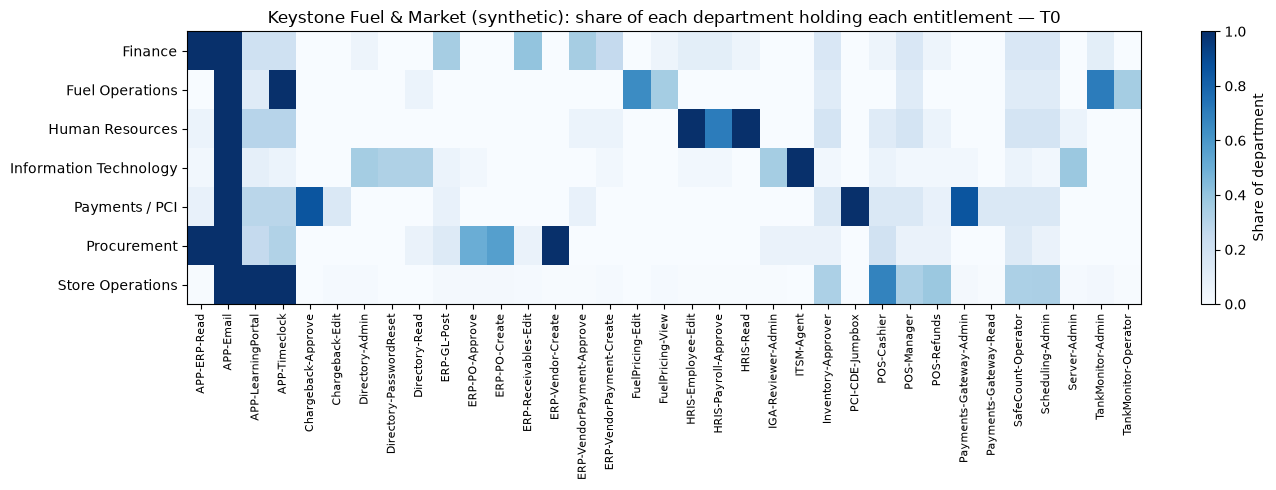

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(prevalence.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(prevalence.index)), prevalence.index)
ax.set_xticks(range(len(prevalence.columns)), prevalence.columns, rotation=90, fontsize=8)
ax.set_title("Keystone Fuel & Market (synthetic): share of each department holding each entitlement — T0")
fig.colorbar(im, ax=ax, label="Share of department")
fig.tight_layout()
fig.savefig(IMG / "m2-dept-entitlement-heatmap-t0.png", dpi=150)
plt.show()

In [11]:
birthright_candidates = prevalence.stack().rename("share").reset_index()
birthright_candidates = birthright_candidates[birthright_candidates["share"] >= 0.90]
print("Department/entitlement pairs held by 90%+ of the department:", len(birthright_candidates))
birthright_candidates.sort_values(["department", "share"], ascending=[True, False])

Department/entitlement pairs held by 90%+ of the department: 17


,department,entitlement,share
0,Finance,APP-ERP-Read,1.0
1,Finance,APP-Email,1.0
36,Fuel Operations,APP-Email,1.0
38,Fuel Operations,APP-Timeclock,1.0
71,Human Resources,APP-Email,1.0
88,Human Resources,HRIS-Employee-Edit,1.0
90,Human Resources,HRIS-Read,1.0
106,Information Technology,APP-Email,1.0
127,Information Technology,ITSM-Agent,1.0
141,Payments / PCI,APP-Email,1.0


## Findings (T0)
- __ active employees hold __ entitlements through __ assignments; the matrix is __% filled.
- __ assignments (__ accounts) have no HR record and were excluded from mining — they are cleanup work, not role input.
- __ department/entitlement pairs are held by 90%+ of a department (birthright candidates).
- Not every 90%+ pair should become automatic access: __ (name one, and say why).
- Next: cluster people by similar access (M2.2) — department alone is too coarse because __.

---
# Role Mining — Part B: Clustering people into candidate roles
Method: Jaccard similarity on the T0 access matrix, average-linkage hierarchical clustering, role core = entitlements held by ≥80% of a cluster.

In [12]:
import numpy as np
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster

REPORTS = ROOT / "reports"
people = active.drop_duplicates("upn").set_index("upn").reindex(matrix.index)[["department", "job_title"]]
print("People:", len(people), "| Entitlements:", matrix.shape[1])

People: 276 | Entitlements: 35


In [13]:
def access_of(upn):
    return set(matrix.columns[matrix.loc[upn] == 1])

def jaccard(a, b):
    return len(a & b) / len(a | b)

associate = people[people["job_title"] == "Store Associate"].index[0]
shift_lead = people[people["job_title"] == "Shift Lead"].index[0]
manager = people[people["job_title"] == "Store Manager"].index[0]

for name, upn in [("Associate", associate), ("Shift Lead", shift_lead), ("Store Manager", manager)]:
    print(f"{name:13} {sorted(access_of(upn))}")
print()
print("Associate vs Shift Lead:    ", round(jaccard(access_of(associate), access_of(shift_lead)), 2))
print("Associate vs Store Manager: ", round(jaccard(access_of(associate), access_of(manager)), 2))

Associate     ['APP-Email', 'APP-LearningPortal', 'APP-Timeclock', 'POS-Cashier']
Shift Lead    ['APP-Email', 'APP-LearningPortal', 'APP-Timeclock', 'POS-Cashier', 'POS-Refunds']
Store Manager ['APP-Email', 'APP-LearningPortal', 'APP-Timeclock', 'Inventory-Approver', 'POS-Manager', 'SafeCount-Operator', 'Scheduling-Admin']

Associate vs Shift Lead:     0.8
Associate vs Store Manager:  0.38


In [14]:
distances = pdist(matrix.values.astype(bool), metric="jaccard")
similarity = 1 - squareform(distances)
pairs = similarity[np.triu_indices(len(similarity), k=1)]
print("Pairs compared:", f"{len(pairs):,}")
print("Average similarity between two people:", round(pairs.mean(), 2))

Pairs compared: 37,950
Average similarity between two people: 0.34


In [15]:
tree = linkage(distances, method="average")

def build_roles(threshold, min_size=5, core_share=0.80):
    labels = pd.Series(fcluster(tree, t=threshold, criterion="distance"), index=matrix.index)
    sizes = labels.value_counts()
    kept = sizes[sizes >= min_size].index
    core = {c: set(matrix.columns[matrix.loc[labels[labels == c].index].mean() >= core_share]) for c in kept}
    covered = sum(len(access_of(u) & core.get(labels[u], set())) for u in matrix.index)
    return labels, kept, core, covered

sweep = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    labels, kept, core, covered = build_roles(t)
    in_role = labels.isin(kept).sum()
    sweep.append({"threshold": t, "candidate_roles": len(kept),
                  "people_in_a_role_pct": round(100 * in_role / len(labels), 1),
                  "access_covered_pct": round(100 * covered / matrix.values.sum(), 1)})
sweep = pd.DataFrame(sweep)
sweep

,threshold,candidate_roles,people_in_a_role_pct,access_covered_pct
0,0.2,12,75.4,69.0
1,0.3,11,79.3,70.2
2,0.4,13,91.7,80.6
3,0.5,12,97.5,84.2
4,0.6,12,99.3,84.6


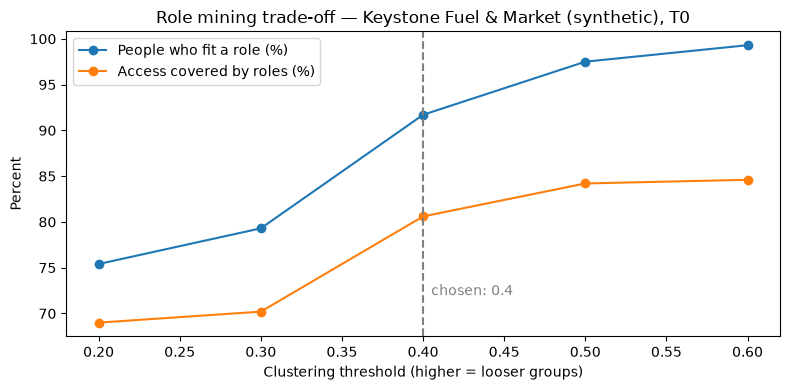

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep["threshold"], sweep["people_in_a_role_pct"], marker="o", label="People who fit a role (%)")
ax.plot(sweep["threshold"], sweep["access_covered_pct"], marker="o", label="Access covered by roles (%)")
ax.axvline(0.4, linestyle="--", color="gray")
ax.text(0.405, 72, "chosen: 0.4", color="gray")
ax.set_xlabel("Clustering threshold (higher = looser groups)")
ax.set_ylabel("Percent")
ax.set_title("Role mining trade-off — Keystone Fuel & Market (synthetic), T0")
ax.legend()
fig.tight_layout()
fig.savefig(IMG / "m2-threshold-sweep.png", dpi=150)
plt.show()

In [17]:
THRESHOLD = 0.4
labels, kept, core, covered = build_roles(THRESHOLD)

rows = []
for c in kept:
    members = labels[labels == c].index
    titles = people.loc[members, "job_title"].value_counts()
    rows.append({"cluster": c, "members": len(members),
                 "main_title": titles.index[0],
                 "main_title_share": round(titles.iloc[0] / len(members), 2),
                 "core_entitlements": ", ".join(sorted(core[c]))})
roles = pd.DataFrame(rows).sort_values(["members", "main_title"], ascending=[False, True]).reset_index(drop=True)
roles.insert(0, "role_id", [f"CR-{i+1:02d}" for i in range(len(roles))])

in_role = labels.isin(kept)
print("Candidate roles:", len(roles))
print(f"People who fit a role: {in_role.sum()} of {len(labels)} ({in_role.mean():.1%})")
print(f"Access covered by role cores: {covered} of {int(matrix.values.sum())} ({covered / matrix.values.sum():.1%})")
roles[["role_id", "members", "main_title", "main_title_share", "core_entitlements"]]

Candidate roles: 13
People who fit a role: 253 of 276 (91.7%)
Access covered by role cores: 1186 of 1472 (80.6%)


,role_id,members,main_title,main_title_share,core_entitlements
0,CR-01,103,Shift Lead,0.55,"APP-Email, APP-LearningPortal, APP-Timeclock, ..."
1,CR-02,64,Store Manager,0.81,"APP-Email, APP-LearningPortal, APP-Timeclock, ..."
2,CR-03,12,HR Manager,0.83,"APP-Email, HRIS-Employee-Edit, HRIS-Payroll-Ap..."
3,CR-04,10,IAM Analyst,1.00,"APP-Email, Directory-Read, IGA-Reviewer-Admin,..."
4,CR-05,10,Service Desk Analyst,1.00,"APP-Email, Directory-PasswordReset, ITSM-Agent"
5,CR-06,10,Systems Administrator,1.00,"APP-Email, Directory-Admin, ITSM-Agent, Server..."
6,CR-07,9,Fuel Operations Manager,1.00,"APP-Email, APP-Timeclock, FuelPricing-Edit, Ta..."
7,CR-08,7,Payments Manager,1.00,"APP-Email, Chargeback-Approve, PCI-CDE-Jumpbox..."
8,CR-09,6,AR Specialist,1.00,"APP-ERP-Read, APP-Email, ERP-Receivables-Edit"
9,CR-10,6,Accounting Manager,1.00,"APP-ERP-Read, APP-Email, ERP-GL-Post, ERP-Vend..."


In [18]:
sod = pd.read_csv(DATA / "sod_rules.csv")
problems = []
for _, role in roles.iterrows():
    ents = core[role["cluster"]]
    for _, rule in sod.iterrows():
        if rule["entitlement_a"] in ents and rule["entitlement_b"] in ents:
            problems.append({"role_id": role["role_id"], "main_title": role["main_title"],
                             "members": role["members"], "sod_rule": rule["description"]})
print("Candidate roles that contain a toxic combination:", len(problems))
pd.DataFrame(problems)

Candidate roles that contain a toxic combination: 1


,role_id,main_title,members,sod_rule
0,CR-03,HR Manager,12,Edit employee records and approve payroll


In [19]:
cluster_to_role = dict(zip(roles["cluster"], roles["role_id"]))
outliers = []
for upn in matrix.index:
    held = access_of(upn)
    if in_role[upn]:
        extra = held - core[labels[upn]]
        if extra:
            outliers.append({"upn": upn, "type": "Extra access beyond role",
                             "role_id": cluster_to_role[labels[upn]], "extra": ", ".join(sorted(extra))})
    else:
        outliers.append({"upn": upn, "type": "No role fit", "role_id": "", "extra": ", ".join(sorted(held))})
outliers = pd.DataFrame(outliers).set_index("upn").join(people)
print(outliers["type"].value_counts())
print()
extra_counts = (outliers[outliers["type"] == "Extra access beyond role"]["extra"]
                .str.split(", ").explode().value_counts())
print("Most common access held outside a role core:")
print(extra_counts.head(5))

type
Extra access beyond role    88
No role fit                 23
Name: count, dtype: int64

Most common access held outside a role core:
extra
POS-Refunds             59
HRIS-Employee-Edit       9
APP-ERP-Read             7
ERP-GL-Post              6
HRIS-Payroll-Approve     6
Name: count, dtype: int64


In [20]:
manager_with_till = outliers[(outliers["job_title"] == "Store Manager") & outliers["extra"].str.contains("POS-Cashier")]
manager_with_till[["department", "job_title", "role_id", "extra"]]

,department,job_title,role_id,extra
upn,,,,
jordan.lindqvist@kqm-lab.example,Store Operations,Store Manager,CR-02,"POS-Cashier, Server-Admin"


In [21]:
roles.drop(columns="cluster").to_csv(REPORTS / "m2-candidate-roles-t0.csv", index=False)
outliers.to_csv(REPORTS / "m2-role-outliers-t0.csv")
print("Saved:", REPORTS / "m2-candidate-roles-t0.csv")
print("Saved:", REPORTS / "m2-role-outliers-t0.csv")

Saved: c:\Users\metzg\Documents\entra-governance\reports\m2-candidate-roles-t0.csv
Saved: c:\Users\metzg\Documents\entra-governance\reports\m2-role-outliers-t0.csv


## Findings — candidate roles (T0)
- Threshold 0.4 produced __ candidate roles covering __ of __ people (__%) and __% of all access.
- Chose 0.4 because: __
- CR-03 (HR Manager) cannot be approved as mined: __
- CR-01 mixes Store Associates and Shift Leads; recommended design: __
- __ people fit no role and __ hold access beyond their role — these go to the M3 access review / M4 anomaly report.